In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.impute import SimpleImputer
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset,DataLoader

In [ ]:
url = '/content/titanic.csv'
df = pd.read_csv(url)



In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [ ]:
df.tail()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [ ]:
#preprocess the data
df = df[['Survived','Pclass','Age','SibSp','Parch','Fare']]
imputer = SimpleImputer(strategy='mean')
df['Age'] = imputer.fit_transform(df[['Age']])

In [ ]:
X = df.drop('Survived', axis=1)
y = df['Survived']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#Random Forest
ran_clf = RandomForestClassifier()
ran_model = ran_clf.fit(X_train, y_train)
ran_pred = ran_model.predict(X_test)
print("Accuracy {0:.2f}%".format(100*accuracy_score(y_test, ran_pred)))
print(confusion_matrix(y_test, ran_pred))
print(classification_report(y_test , ran_pred))

Accuracy 70.39%
[[85 20]
 [33 41]]
              precision    recall  f1-score   support

           0       0.72      0.81      0.76       105
           1       0.67      0.55      0.61        74

    accuracy                           0.70       179
   macro avg       0.70      0.68      0.68       179
weighted avg       0.70      0.70      0.70       179



In [ ]:
#Gradient boosting classifier
gradient_clf = GradientBoostingClassifier()
gradient_model = gradient_clf.fit(X_train, y_train)
gradient_pred = gradient_model.predict(X_test)
print("Accuracy {0:.2f}%".format(100*accuracy_score(y_test, gradient_pred)))
print(confusion_matrix(y_test, gradient_pred))
print(classification_report(y_test , gradient_pred))

Accuracy 71.51%
[[97  8]
 [43 31]]
              precision    recall  f1-score   support

           0       0.69      0.92      0.79       105
           1       0.79      0.42      0.55        74

    accuracy                           0.72       179
   macro avg       0.74      0.67      0.67       179
weighted avg       0.74      0.72      0.69       179



In [ ]:
#KNN
from sklearn.neighbors import KNeighborsClassifier
knn_clf = KNeighborsClassifier(n_neighbors=3)
knn_model = knn_clf.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
print("Accuracy {0:.2f}%".format(100*accuracy_score(y_test, knn_pred)))
print(confusion_matrix(y_test, knn_pred))
print(classification_report(y_test , knn_pred))

Accuracy 72.63%
[[86 19]
 [30 44]]
              precision    recall  f1-score   support

           0       0.74      0.82      0.78       105
           1       0.70      0.59      0.64        74

    accuracy                           0.73       179
   macro avg       0.72      0.71      0.71       179
weighted avg       0.72      0.73      0.72       179



In [ ]:
#SVM
from sklearn.svm import SVC
svm_clf = SVC()
svm_model = svm_clf.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
print("Accuracy {0:.2f}%".format(100*accuracy_score(y_test, svm_pred)))
print(confusion_matrix(y_test, svm_pred))
print(classification_report(y_test , svm_pred))

Accuracy 74.30%
[[98  7]
 [39 35]]
              precision    recall  f1-score   support

           0       0.72      0.93      0.81       105
           1       0.83      0.47      0.60        74

    accuracy                           0.74       179
   macro avg       0.77      0.70      0.71       179
weighted avg       0.76      0.74      0.72       179



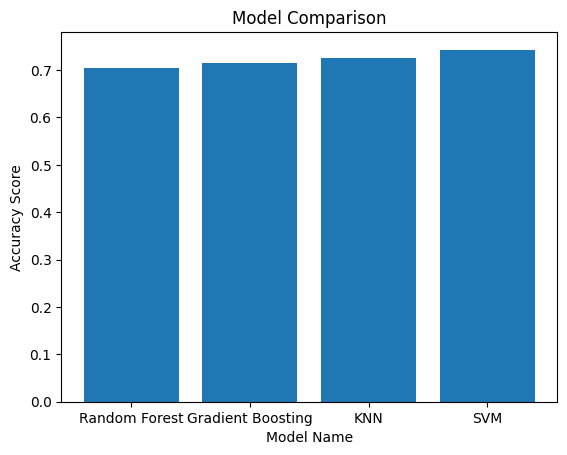

In [ ]:
# Compare the accuracy of different models
models = ['Random Forest', 'Gradient Boosting', 'KNN', 'SVM']
accuracy = [accuracy_score(y_test, ran_pred), accuracy_score(y_test, gradient_pred), accuracy_score(y_test, knn_pred), accuracy_score(y_test, svm_pred)]
plt.bar(models, accuracy)
plt.xlabel('Model Name')
plt.ylabel('Accuracy Score')
plt.title('Model Comparison')
plt.show()